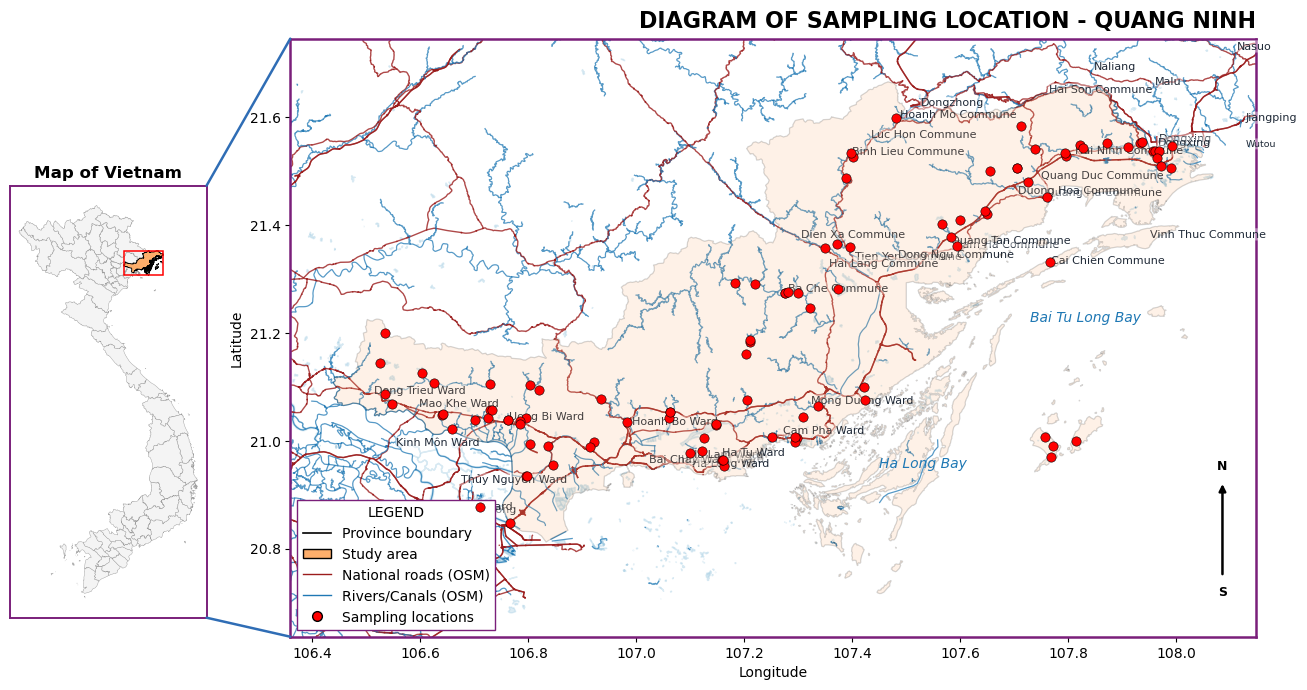

In [ ]:
import os
import zipfile
import urllib.request
import urllib.parse
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.lines import Line2D
import numpy as np

# ==========================================
# 1. ĐỌC DỮ LIỆU BẢN ĐỒ QUẢNG NINH (GADM - CHI TIẾT HƠN)
# ==========================================
gadm_zip_url = "https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_VNM_shp.zip"
data_dir = "_mapdata_gadm"
os.makedirs(data_dir, exist_ok=True)
zip_path = os.path.join(data_dir, "gadm41_VNM_shp.zip")
shp_path = os.path.join(data_dir, "gadm41_VNM_1.shp")

if not os.path.exists(shp_path):
    if not os.path.exists(zip_path):
        urllib.request.urlretrieve(gadm_zip_url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_dir)

vn_map = gpd.read_file(shp_path).to_crs("EPSG:4326")
qn_map = vn_map[vn_map["NAME_1"].astype(str).str.contains(r"Quang Ninh|Quảng Ninh", case=False, na=False)]
if qn_map.empty:
    raise ValueError("Không tìm thấy Quảng Ninh trong dữ liệu GADM")

# ==========================================
# 2. ĐỌC SAMPLING LOCATIONS TỪ FILE EXCEL
# ==========================================
xlsx_path = "quang_ninh_wqi_fig.xlsx"
try:
    df_raw = pd.read_excel(xlsx_path, sheet_name=0)
except PermissionError as exc:
    raise PermissionError(
        f"Không thể đọc {xlsx_path} vì file đang bị khóa. Hãy đóng file trong Excel rồi chạy lại Cell 1."
    ) from exc

normalized_cols = {
    c: str(c).strip().lower().replace(" ", "").replace("_", "")
    for c in df_raw.columns
}

def pick_column(candidates):
    for original, normalized in normalized_cols.items():
        if normalized in candidates:
            return original
    return None

station_col = pick_column({
    "station", "stationname", "sitename", "location", "samplinglocation", "samplingpoint",
    "tram", "tentram", "diemlaymau", "vitrilaymau"
})
lon_col = pick_column({
    "longitude", "lon", "x", "kinhdo", "toadox", "long"
})
lat_col = pick_column({
    "latitude", "lat", "y", "vido", "toadoy"
})

if lon_col is None or lat_col is None:
    raise ValueError(
        "Không tìm thấy cột Longitude/Latitude trong quang_ninh_wqi_fig.xlsx. "
        f"Các cột hiện có: {list(df_raw.columns)}"
    )

if station_col is None:
    station_col = "Station"
    df_raw[station_col] = [f"Station {i+1}" for i in range(len(df_raw))]

df_stations = df_raw[[station_col, lon_col, lat_col]].copy()
df_stations.columns = ["Station", "Longitude", "Latitude"]

df_stations["Longitude"] = pd.to_numeric(
    df_stations["Longitude"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
df_stations["Latitude"] = pd.to_numeric(
    df_stations["Latitude"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)

df_stations = df_stations.replace([np.inf, -np.inf], np.nan).dropna(subset=["Longitude", "Latitude"])

direct_valid = (
    df_stations["Longitude"].between(100, 110) &
    df_stations["Latitude"].between(18, 23)
).sum()
swapped_valid = (
    df_stations["Latitude"].between(100, 110) &
    df_stations["Longitude"].between(18, 23)
).sum()
if swapped_valid > direct_valid:
    df_stations[["Longitude", "Latitude"]] = df_stations[["Latitude", "Longitude"]].to_numpy()

df_stations = df_stations[
    (df_stations["Longitude"].between(100, 110)) &
    (df_stations["Latitude"].between(18, 23))
]
df_stations = df_stations.reset_index(drop=True)

if df_stations.empty:
    raise ValueError(
        "Không có sampling location hợp lệ sau khi lọc tọa độ. "
        "Kiểm tra lại cột Longitude/Latitude trong file Excel (kỳ vọng lon ~100-110, lat ~18-23)."
    )

stations_gdf = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations.Longitude, df_stations.Latitude),
    crs="EPSG:4326",
)

# ==========================================
# 3. TẢI LỚP OSM: ĐỊA DANH LỚN + QUỐC LỘ + SÔNG/HỒ
# ==========================================
def fetch_osm_layers(west, south, east, north):
    query = f"""
    [out:json][timeout:90];
    (
      way[\"highway\"~\"motorway|trunk|primary\"]({south},{west},{north},{east});
      way[\"waterway\"~\"river|stream|canal\"]({south},{west},{north},{east});
      way[\"natural\"=\"water\"]({south},{west},{north},{east});
      node[\"place\"~\"city|town|village|suburb\"][\"name:en\"]({south},{west},{north},{east});
    );
    (._;>;);
    out body;
    """
    url = "https://overpass-api.de/api/interpreter"
    data = urllib.parse.urlencode({"data": query}).encode("utf-8")
    req = urllib.request.Request(url, data=data, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.loads(r.read().decode("utf-8"))

# ==========================================
# 4. VẼ THEO FORM MẪU + LỚP BẢN ĐỒ NỀN OSM
# ==========================================
fig = plt.figure(figsize=(14, 8))
ax_main = fig.add_axes([0.28, 0.10, 0.69, 0.82])

xmin, ymin, xmax, ymax = qn_map.total_bounds
buffer = 0.08
west, south, east, north = xmin - buffer, ymin - buffer, xmax + buffer, ymax + buffer
ax_main.set_xlim(west, east)
ax_main.set_ylim(south, north)

# Vẽ lớp OSM (nếu tải được)
try:
    osm_data = fetch_osm_layers(west, south, east, north)
    nodes = {e["id"]: (e["lon"], e["lat"]) for e in osm_data["elements"] if e["type"] == "node" and "lon" in e and "lat" in e}

    place_labels = []
    for e in osm_data["elements"]:
        if e["type"] == "way" and "nodes" in e:
            tags = e.get("tags", {})
            coords = [nodes[n] for n in e["nodes"] if n in nodes]
            if len(coords) < 2:
                continue
            xs = [c[0] for c in coords]
            ys = [c[1] for c in coords]

            if "highway" in tags:
                ax_main.plot(xs, ys, color="#9b1c1c", linewidth=1.0, alpha=0.8, zorder=1)
            elif "waterway" in tags:
                ax_main.plot(xs, ys, color="#1f78b4", linewidth=0.9, alpha=0.75, zorder=1)
            elif tags.get("natural") == "water":
                if coords[0] == coords[-1]:
                    ax_main.fill(xs, ys, color="#9ecae1", alpha=0.35, zorder=0)
                else:
                    ax_main.plot(xs, ys, color="#6baed6", linewidth=0.8, alpha=0.7, zorder=0)

        if e["type"] == "node":
            tags = e.get("tags", {})
            if tags.get("place") in {"city", "town", "village", "suburb"} and "name:en" in tags:
                place_labels.append((e["lon"], e["lat"], tags["name:en"], tags.get("place")))

    # Tăng mật độ nhãn, ưu tiên góc trên phải
    priority = {"city": 0, "town": 1, "village": 2, "suburb": 3}
    place_labels = sorted(place_labels, key=lambda x: priority.get(x[3], 9))

    mid_lon = (west + east) / 2
    mid_lat = (south + north) / 2
    ne_labels = [p for p in place_labels if p[0] >= mid_lon and p[1] >= mid_lat][:25]

    chosen = ne_labels.copy()
    chosen_names = {p[2] for p in chosen}
    for p in place_labels:
        if p[2] not in chosen_names:
            chosen.append(p)
            chosen_names.add(p[2])
        if len(chosen) >= 40:
            break

    for lon, lat, name, ptype in chosen:
        ax_main.text(
            lon, lat, name,
            fontsize=8 if ptype in {"city", "town"} else 6.8,
            color="#1f2937",
            zorder=3,
            ha="left", va="bottom",
            bbox=dict(boxstyle="round,pad=0.10", facecolor="white", edgecolor="none", alpha=0.42),
        )
except Exception as exc:
    print(f"Không tải được lớp OSM (địa danh/đường/sông hồ): {exc}")

# Lớp ranh giới + điểm trạm
qn_map.plot(ax=ax_main, color="#fdae6b", alpha=0.16, edgecolor="black", linewidth=0.9, zorder=4)
stations_gdf.plot(
    ax=ax_main, color="red", marker="o", markersize=45, edgecolor="black", linewidth=0.4, zorder=6
)

# English bay names
ax_main.text(107.45, 20.95, "Ha Long Bay", fontsize=10, color="#1f78b4", fontstyle="italic", zorder=7)
ax_main.text(107.73, 21.22, "Bai Tu Long Bay", fontsize=10, color="#1f78b4", fontstyle="italic", zorder=7)

# North-South arrow at lower-right
ax_main.annotate(
    "",
    xy=(0.965, 0.26),
    xytext=(0.965, 0.10),
    xycoords="axes fraction",
    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8),
)
ax_main.text(0.965, 0.275, "N", transform=ax_main.transAxes, ha="center", va="bottom", fontsize=9, fontweight="bold")
ax_main.text(0.965, 0.085, "S", transform=ax_main.transAxes, ha="center", va="top", fontsize=9, fontweight="bold")

ax_main.set_aspect("equal")
ax_main.grid(False)
for spine in ax_main.spines.values():
    spine.set_linewidth(1.8)
    spine.set_color("#7a1f7a")

ax_main.set_title("DIAGRAM OF SAMPLING LOCATION - QUANG NINH", fontsize=16, fontweight="bold", loc="right", pad=8)
ax_main.set_xlabel("Longitude")
ax_main.set_ylabel("Latitude")

# Inset map (left)
ax_inset = fig.add_axes([0.06, 0.16, 0.18, 0.54])
vn_map.plot(ax=ax_inset, color="#f4f4f4", edgecolor="#9d9d9d", linewidth=0.3)
qn_map.plot(ax=ax_inset, color="#fdae6b", edgecolor="black", linewidth=0.6)
ax_inset.set_title("Map of Vietnam", fontsize=12, fontweight="bold", pad=6)
ax_inset.set_xticks([])
ax_inset.set_yticks([])
for spine in ax_inset.spines.values():
    spine.set_linewidth(1.4)
    spine.set_color("#7a1f7a")

rect_inset = Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, ec="red", lw=1.1)
ax_inset.add_patch(rect_inset)

con1 = ConnectionPatch(
    xyA=(1.0, 1.0), coordsA=ax_inset.transAxes,
    xyB=(0.0, 1.0), coordsB=ax_main.transAxes,
    color="#2f6db5", linewidth=1.8
)
con2 = ConnectionPatch(
    xyA=(1.0, 0.0), coordsA=ax_inset.transAxes,
    xyB=(0.0, 0.0), coordsB=ax_main.transAxes,
    color="#2f6db5", linewidth=1.8
)
fig.add_artist(con1)
fig.add_artist(con2)

legend_handles = [
    Line2D([0], [0], color="black", lw=1.2, label="Province boundary"),
    Rectangle((0, 0), 1, 1, facecolor="#fdae6b", edgecolor="black", label="Study area"),
    Line2D([0], [0], color="#9b1c1c", lw=1.0, label="National roads (OSM)"),
    Line2D([0], [0], color="#1f78b4", lw=1.0, label="Rivers/Canals (OSM)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markeredgecolor="black", markersize=7, label="Sampling locations"),
]
ax_main.legend(
    handles=legend_handles,
    title="LEGEND",
    loc="lower left",
    frameon=True,
    framealpha=1.0,
    edgecolor="#7a1f7a",
    fancybox=False,
)

plt.show()
